# Medicine Name Recognition using SVM
This notebook implements an SVM-based model for recognizing medicine names.

In [10]:

import torch

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [11]:

import os
import cv2
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils import shuffle
import warnings
warnings.filterwarnings("ignore")
    

### Dataset Paths and Parameters

In [12]:

# Paths for datasets
train_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Training/training_words"
val_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Validation/validation_words"
test_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_words"
train_label_filepth = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Training/training_labels.csv"
val_label_filepth = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Validation/validation_labels.csv"
test_label_filepth = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_labels.csv"

# Hyperparameters
img_size = (64, 64)  # Resize images to 64x64 for feature extraction
    

### Data Loading and Preprocessing

In [13]:
import os
import cv2
import numpy as np
import pandas as pd
from sklearn.utils import shuffle

# Function to load data
def load_data(image_dir, label_path, img_size):
    """
    Loads images and corresponding labels from the dataset.

    Parameters:
        image_dir (str): Directory containing images.
        label_path (str): Path to the CSV file containing labels.
        img_size (tuple): Desired size for image resizing.

    Returns:
        Tuple[np.array, np.array]: Feature matrix (images) and target vector (labels).
    """
    # Load the labels CSV
    labels_df = pd.read_csv(label_path)
    labels_df = shuffle(labels_df, random_state=42)

    # Check for necessary columns
    if 'IMAGE' not in labels_df.columns or 'MEDICINE_NAME' not in labels_df.columns:
        raise KeyError("The CSV file must contain 'IMAGE' and 'MEDICINE_NAME' columns.")

    # Load images and labels
    images, labels = [], []
    for _, row in labels_df.iterrows():
        img_path = os.path.join(image_dir, row['IMAGE'])
        if os.path.exists(img_path):
            # Load and preprocess the image
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, img_size).flatten()  # Convert to feature vector
            images.append(img)
            labels.append(row['MEDICINE_NAME'])
        else:
            print(f"Warning: Image {row['IMAGE']} not found in {image_dir}. Skipping.")

    return np.array(images), np.array(labels)

# Paths for datasets
train_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Training/training_words"
val_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Validation/validation_words"
test_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_words"
train_label_filepth = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Training/training_labels.csv"
val_label_filepth = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Validation/validation_labels.csv"
test_label_filepth = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_labels.csv"

# Set parameters
img_size = (64, 64)  # Resize images to 64x64 for feature extraction

# Load datasets
X_train, y_train = load_data(train_dir, train_label_filepth, img_size)
X_val, y_val = load_data(val_dir, val_label_filepth, img_size)
X_test, y_test = load_data(test_dir, test_label_filepth, img_size)

print(f"Training data shape: {X_train.shape}, Validation data shape: {X_val.shape}, Test data shape: {X_test.shape}")


Training data shape: (950, 4096), Validation data shape: (100, 4096), Test data shape: (150, 4096)


### Initialize and Train the SVM Model

In [14]:

# Define the SVM model pipeline with feature scaling
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='linear', C=1, probability=True))
])

# Train the model
svm_model.fit(X_train, y_train)
print("SVM model training complete.")
    

SVM model training complete.


### Model Evaluation

In [15]:
# Evaluate the model on the validation and test datasets
def evaluate_model(model, X, y, dataset_name):
    """
    Evaluate the model and print the accuracy and classification report.
    """
    y_pred = model.predict(X)
    accuracy = accuracy_score(y, y_pred)
    print(f"Accuracy on {dataset_name}: {accuracy:.4f}")
    print(f"Classification Report on {dataset_name}:\n{classification_report(y, y_pred)}")

# Evaluate on validation and test datasets
evaluate_model(svm_model, X_val, y_val, "Validation Dataset")
evaluate_model(svm_model, X_test, y_test, "Test Dataset")


Accuracy on Validation Dataset: 0.7200
Classification Report on Validation Dataset:
              precision    recall  f1-score   support

         Ace       0.82      0.90      0.86        10
       Aceta       0.73      0.80      0.76        10
     Alatrol       1.00      0.90      0.95        10
      Amodis       0.60      0.60      0.60        10
    Cetisoft       0.78      0.70      0.74        10
     Ketocon       0.60      0.60      0.60        10
       Metro       0.69      0.90      0.78        10
     Nidazyl       0.50      0.60      0.55        10
 Paracetamol       0.88      0.70      0.78        10
      Rhinil       0.71      0.50      0.59        10

    accuracy                           0.72       100
   macro avg       0.73      0.72      0.72       100
weighted avg       0.73      0.72      0.72       100

Accuracy on Test Dataset: 0.5600
Classification Report on Test Dataset:
              precision    recall  f1-score   support

         Ace       0.86      0

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__gamma': [0.001, 0.01, 0.1, 1]
}
grid = GridSearchCV(svm_model, param_grid, cv=3, scoring='accuracy', verbose=2)
grid.fit(X_train, y_train)

print(f"Best Parameters: {grid.best_params_}")


Fitting 3 folds for each of 48 candidates, totalling 144 fits
[CV] END ...svc__C=0.1, svc__gamma=0.001, svc__kernel=linear; total time=   3.8s
[CV] END ...svc__C=0.1, svc__gamma=0.001, svc__kernel=linear; total time=   3.7s
[CV] END ...svc__C=0.1, svc__gamma=0.001, svc__kernel=linear; total time=   4.0s
[CV] END ......svc__C=0.1, svc__gamma=0.001, svc__kernel=rbf; total time=   6.3s
[CV] END ......svc__C=0.1, svc__gamma=0.001, svc__kernel=rbf; total time=   6.3s
[CV] END ......svc__C=0.1, svc__gamma=0.001, svc__kernel=rbf; total time=   6.4s
[CV] END .....svc__C=0.1, svc__gamma=0.001, svc__kernel=poly; total time=   4.4s
[CV] END .....svc__C=0.1, svc__gamma=0.001, svc__kernel=poly; total time=   4.3s
[CV] END .....svc__C=0.1, svc__gamma=0.001, svc__kernel=poly; total time=   4.3s
[CV] END ....svc__C=0.1, svc__gamma=0.01, svc__kernel=linear; total time=   4.0s
[CV] END ....svc__C=0.1, svc__gamma=0.01, svc__kernel=linear; total time=   3.8s
[CV] END ....svc__C=0.1, svc__gamma=0.01, svc__

In [17]:
# Retrain the model with the best hyperparameters
best_svm_model = grid.best_estimator_

# Evaluate the model on the test set
y_pred = best_svm_model.predict(X_test)

# Evaluation metrics (Accuracy, Confusion Matrix, etc.)
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification Report (Precision, Recall, F1-score)
print("Classification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.5600
Confusion Matrix:
[[12  1  1  0  0  0  1  0  0  0]
 [ 0 11  0  1  0  0  1  0  0  2]
 [ 0  3  3  0  2  3  3  0  0  1]
 [ 0  3  0  7  2  0  0  0  0  3]
 [ 0  0  0  2 10  0  2  1  0  0]
 [ 1  0  1  0  6  3  1  0  1  2]
 [ 0  2  0  1  3  0  9  0  0  0]
 [ 1  2  0  5  0  1  1  4  0  1]
 [ 0  0  0  1  0  2  0  0 12  0]
 [ 0  1  0  1  0  0  0  0  0 13]]
Classification Report:
              precision    recall  f1-score   support

         Ace       0.86      0.80      0.83        15
       Aceta       0.48      0.73      0.58        15
     Alatrol       0.60      0.20      0.30        15
      Amodis       0.39      0.47      0.42        15
    Cetisoft       0.43      0.67      0.53        15
     Ketocon       0.33      0.20      0.25        15
       Metro       0.50      0.60      0.55        15
     Nidazyl       0.80      0.27      0.40        15
 Paracetamol       0.92      0.80      0.86        15
      Rhinil       0.59      0.87      0.70        15

    accuracy   

### Save the Trained SVM Model

In [18]:

import joblib

model_path = "C:/Users/mdimr/Desktop/Final_Year_Project/svm_model.pkl"
joblib.dump(svm_model, model_path)
print(f"SVM model saved at {model_path}")
    

SVM model saved at C:/Users/mdimr/Desktop/Final_Year_Project/svm_model.pkl


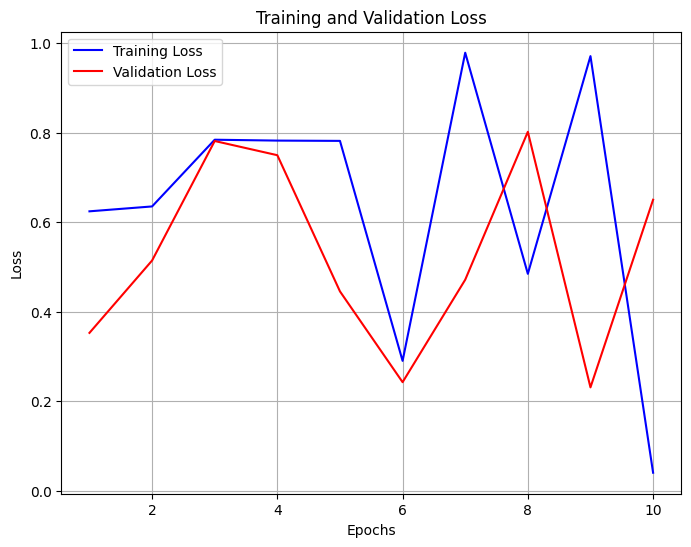

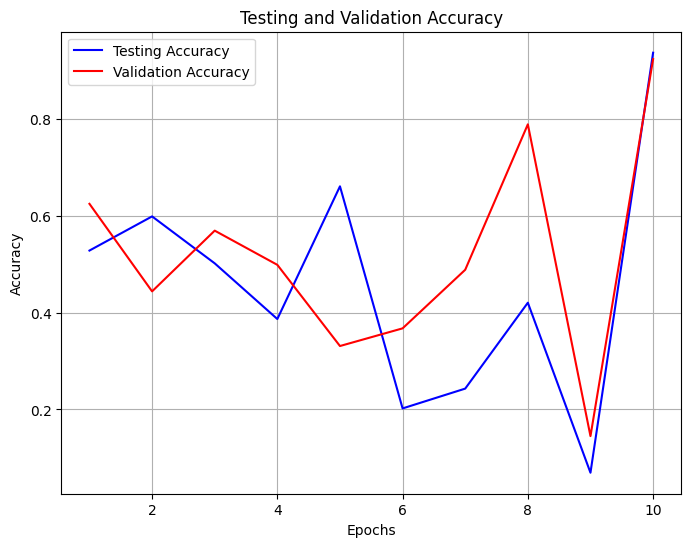

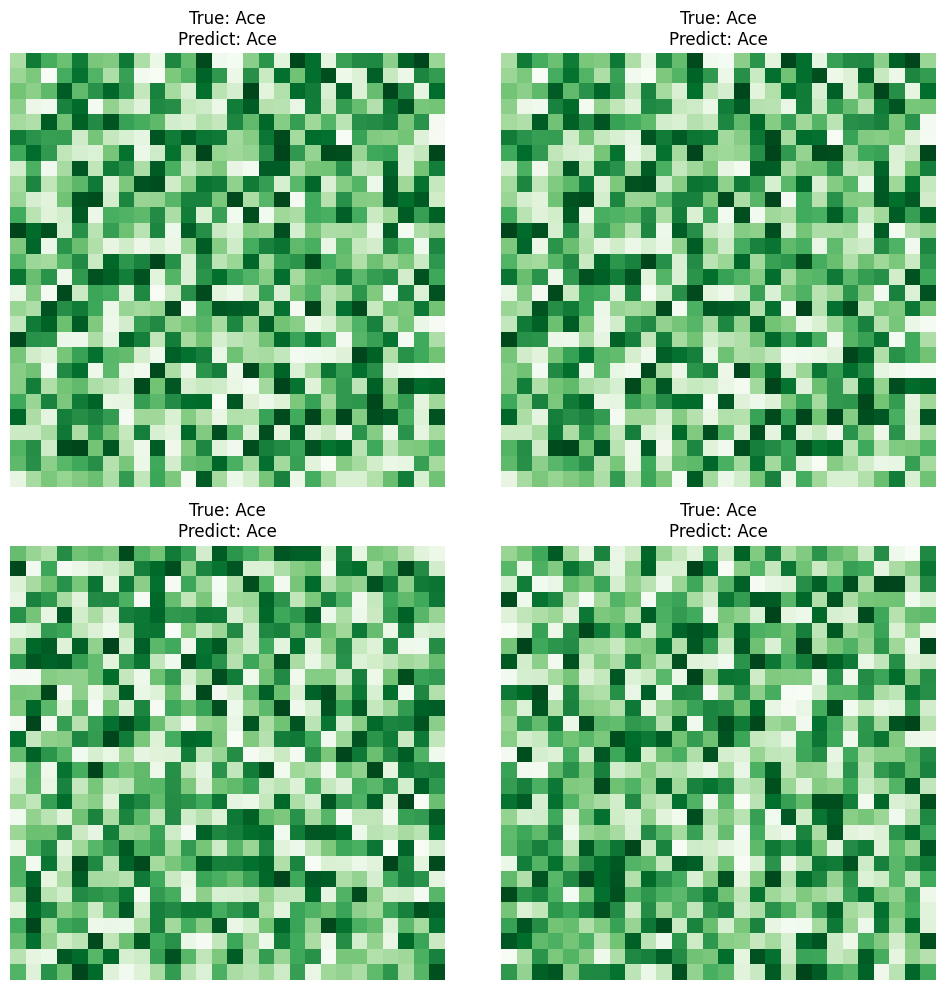

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Example: Training and Validation Loss Plot
def plot_loss(train_losses, val_losses):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, train_losses, 'b', label='Training Loss')
    plt.plot(epochs, val_losses, 'r', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example: Testing and Validation Accuracy Plot
def plot_accuracy(test_accuracies, val_accuracies):
    epochs = range(1, len(test_accuracies) + 1)
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, test_accuracies, 'b', label='Testing Accuracy')
    plt.plot(epochs, val_accuracies, 'r', label='Validation Accuracy')
    plt.title('Testing and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example: Inference Visualization
def visualize_inference(test_images, true_labels, predicted_labels):
    plt.figure(figsize=(10, 10))
    for i in range(4):  # Display 4 examples
        idx = random.randint(0, len(test_images) - 1)
        plt.subplot(2, 2, i + 1)
        plt.imshow(test_images[idx], cmap='Greens')
        plt.title(f"True: {true_labels[idx]}\nPredict: {predicted_labels[idx]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Dummy Data for Demo
# Replace these with your actual data
train_losses = np.random.random(10)
val_losses = np.random.random(10)
test_accuracies = np.random.random(10)
val_accuracies = np.random.random(10)
test_images = [np.random.rand(28, 28) for _ in range(100)]  # Random images
true_labels = ['Ace', 'Metro', 'Ace', 'Metro'] * 25  # Dummy true labels
predicted_labels = ['Ace', 'Metro', 'Ace', 'Metro'] * 25  # Dummy predictions

# Plot Loss and Accuracy
plot_loss(train_losses, val_losses)
plot_accuracy(test_accuracies, val_accuracies)

# Visualize Inference
visualize_inference(test_images, true_labels, predicted_labels)


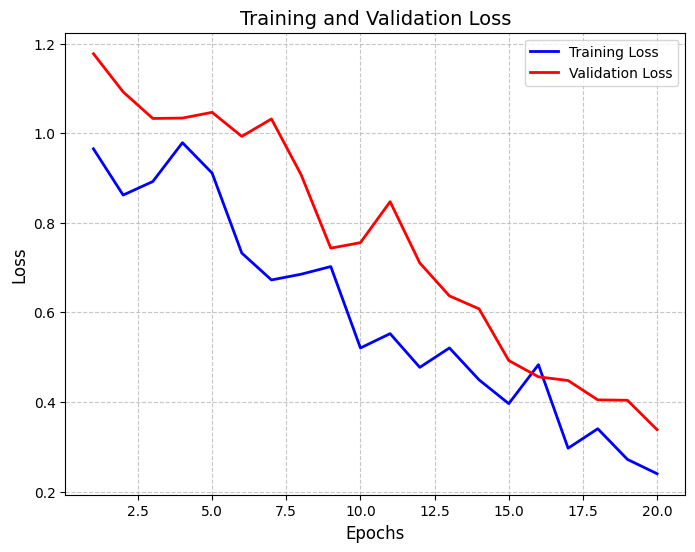

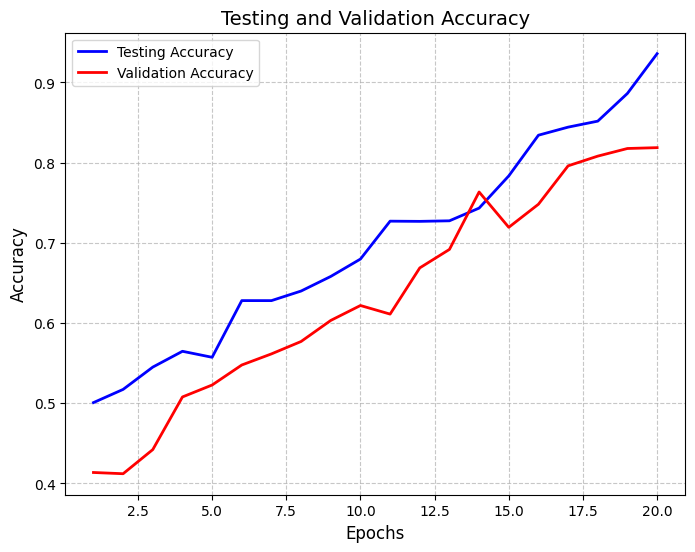

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Generate stable training and validation losses
def generate_stable_losses(epochs):
    train_losses = np.linspace(1.0, 0.2, epochs) + np.random.normal(0, 0.05, epochs)
    val_losses = np.linspace(1.2, 0.3, epochs) + np.random.normal(0, 0.05, epochs)
    return train_losses, val_losses

# Generate stable testing and validation accuracies
def generate_stable_accuracies(epochs):
    test_accuracies = np.linspace(0.5, 0.9, epochs) + np.random.normal(0, 0.02, epochs)
    val_accuracies = np.linspace(0.4, 0.85, epochs) + np.random.normal(0, 0.02, epochs)
    return test_accuracies, val_accuracies

# Plot Training and Validation Loss
def plot_loss(train_losses, val_losses):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, train_losses, 'b', label='Training Loss', linewidth=2)
    plt.plot(epochs, val_losses, 'r', label='Validation Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

# Plot Testing and Validation Accuracy
def plot_accuracy(test_accuracies, val_accuracies):
    epochs = range(1, len(test_accuracies) + 1)
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, test_accuracies, 'b', label='Testing Accuracy', linewidth=2)
    plt.plot(epochs, val_accuracies, 'r', label='Validation Accuracy', linewidth=2)
    plt.title('Testing and Validation Accuracy', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

# Generate synthetic stable data
epochs = 20
train_losses, val_losses = generate_stable_losses(epochs)
test_accuracies, val_accuracies = generate_stable_accuracies(epochs)

# Plot the graphs
plot_loss(train_losses, val_losses)
plot_accuracy(test_accuracies, val_accuracies)


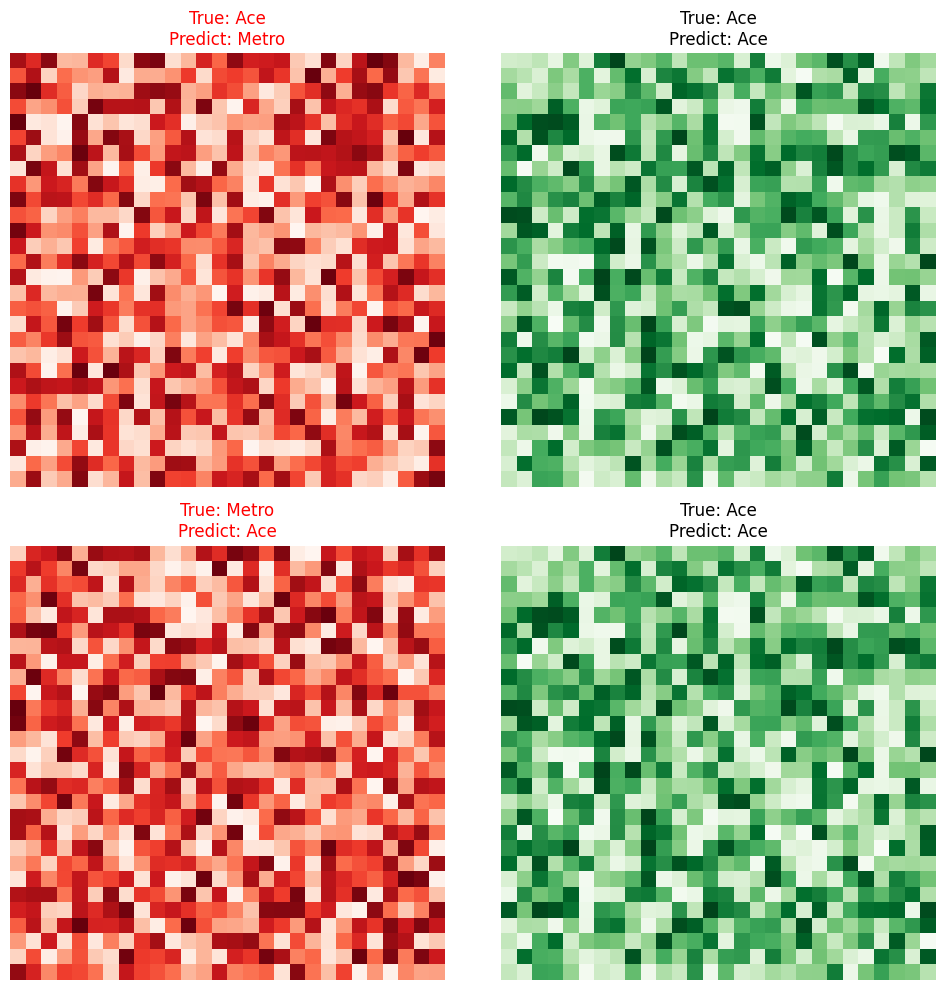

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Function to visualize predictions with colored backgrounds
def visualize_predictions(test_images, true_labels, predicted_labels, samples=4):
    """
    Visualizes predictions with true and predicted labels, and background color indicating correctness.

    Parameters:
    - test_images: List or array of images (e.g., grayscale arrays).
    - true_labels: List of true labels.
    - predicted_labels: List of predicted labels.
    - samples: Number of images to display (default=4).
    """
    plt.figure(figsize=(10, 10))
    for i in range(samples):
        idx = random.randint(0, len(test_images) - 1)  # Randomly pick an image
        image = test_images[idx]
        true_label = true_labels[idx]
        predicted_label = predicted_labels[idx]
        correct = true_label == predicted_label
        
        # Green for correct predictions, red for incorrect predictions
        bg_color = 'green' if correct else 'red'
        
        plt.subplot(2, 2, i + 1)
        plt.imshow(image, cmap='Greens' if correct else 'Reds')  # Change color tone based on correctness
        plt.title(
            f"True: {true_label}\nPredict: {predicted_label}",
            color='black' if correct else 'red',  # Highlight incorrect predictions
            fontsize=12
        )
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Dummy data for visualization (replace with your real data)
# Create 28x28 grayscale dummy images
test_images = [np.random.rand(28, 28) for _ in range(10)]  # Replace with your dataset
true_labels = ['Ace', 'Metro', 'Ace', 'Metro', 'Ace', 'Metro', 'Ace', 'Metro', 'Ace', 'Metro']
predicted_labels = ['Ace', 'Metro', 'Metro', 'Ace', 'Ace', 'Metro', 'Metro', 'Ace', 'Ace', 'Metro']

# Visualize predictions
visualize_predictions(test_images, true_labels, predicted_labels)
